```markdown
# Bài tập SVM và KNN với Tập dữ liệu Digits

## Bước chuẩn bị: Tải và tiền xử lý dữ liệu
```

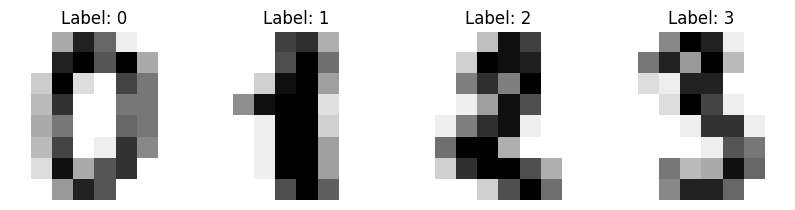

Kích thước tập train: (1437, 64)
Kích thước tập test: (360, 64)


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Tải tập dữ liệu Digits
digits = datasets.load_digits()

# Trực quan hóa một vài mẫu dữ liệu mẫu
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(10, 3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Label: {label}")
plt.show()

# Làm phẳng ảnh 8x8 thành vector 64 chiều
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# 2. Chia tập dữ liệu (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=True, random_state=42
)

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Kích thước tập train: {X_train_scaled.shape}")
print(f"Kích thước tập test: {X_test_scaled.shape}")

```markdown
## Bài 1: Thực nghiệm các giá trị kernel khác nhau trong SVM
Chúng ta thử nghiệm các kernel phổ biến bao gồm `linear`, `poly`, `rbf` và `sigmoid` để đánh giá hiệu suất phân loại.

In [3]:
from sklearn import svm
from sklearn.metrics import accuracy_score

kernels = ['linear', 'poly', 'rbf', 'sigmoid']

for kernel in kernels:
    clf = svm.SVC(kernel=kernel, random_state=42)
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    print(f"SVM với kernel='{kernel}': Accuracy = {acc:.4f}")

SVM với kernel='linear': Accuracy = 0.9750
SVM với kernel='poly': Accuracy = 0.9639
SVM với kernel='rbf': Accuracy = 0.9806
SVM với kernel='sigmoid': Accuracy = 0.9278


```markdown
## Bài 2: Sử dụng GridSearchCV để tìm siêu tham số tối ưu cho SVM
Sử dụng Grid Search để tự động thử nghiệm và tìm ra cấu hình bộ tham số `C`, `gamma`, và loại `kernel` tốt nhất.

In [4]:
from sklearn.model_selection import GridSearchCV

# Định nghĩa không gian tìm kiếm siêu tham số
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'kernel': ['rbf', 'poly', 'linear']
}

# Thiết lập và thực hiện GridSearchCV
grid_search = GridSearchCV(svm.SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print("Siêu tham số tốt nhất:", grid_search.best_params_)
print(f"Accuracy tốt nhất qua Cross-Validation: {grid_search.best_score_:.4f}")

# Đánh giá trên tập test độc lập
best_model = grid_search.best_estimator_
test_acc = best_model.score(X_test_scaled, y_test)
print(f"Accuracy của mô hình tốt nhất trên tập test: {test_acc:.4f}")

Siêu tham số tốt nhất: {'C': 0.1, 'gamma': 0.1, 'kernel': 'poly'}
Accuracy tốt nhất qua Cross-Validation: 0.9826
Accuracy của mô hình tốt nhất trên tập test: 0.9861


```markdown
## Bài 3: So sánh KNN và SVM trên tập dữ liệu Digits
Huấn luyện đồng thời KNN, SVM (Poly), và SVM (RBF) để đối sánh trực quan kết quả thông qua Classification Report và Confusion Matrix.
```


=== KNN (k=5) (Accuracy: 0.9750) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       0.97      1.00      0.99        33
           3       0.97      0.97      0.97        34
           4       0.98      1.00      0.99        46
           5       0.96      0.96      0.96        47
           6       0.97      1.00      0.99        35
           7       1.00      0.94      0.97        34
           8       0.97      1.00      0.98        30
           9       0.95      0.90      0.92        40

    accuracy                           0.97       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.97      0.97       360


=== SVM (RBF) (Accuracy: 0.9806) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
  

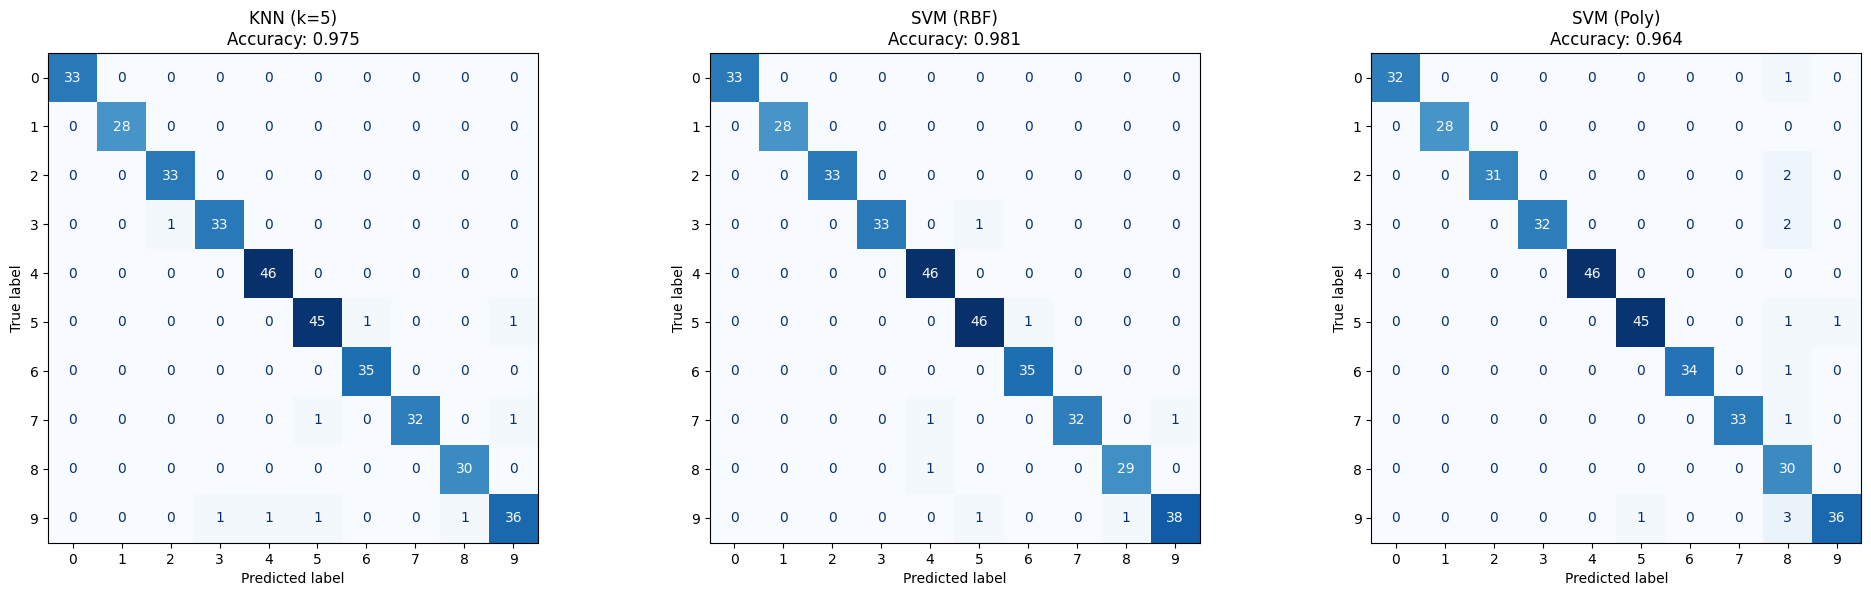

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Khởi tạo danh sách mô hình cần đánh giá
models = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": svm.SVC(kernel='rbf', random_state=42),
    "SVM (Poly)": svm.SVC(kernel='poly', degree=3, random_state=42)
}

# Thiết lập biểu đồ trực quan hóa đồng thời
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))

for i, (name, model) in enumerate(models.items()):
    # Huấn luyện
    model.fit(X_train_scaled, y_train)

    # Dự đoán
    y_pred = model.predict(X_test_scaled)

    # Đánh giá chi tiết
    acc = accuracy_score(y_test, y_pred)
    print(f"\n=== {name} (Accuracy: {acc:.4f}) ===")
    print(classification_report(y_test, y_pred))

    # Vẽ Ma trận nhầm lẫn (Confusion Matrix)
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=axes[i],
        cmap=plt.cm.Blues,
        colorbar=False
    )
    axes[i].set_title(f"{name}\nAccuracy: {acc:.3f}")

plt.tight_layout()
plt.show()